In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repository root, so that `import src` works
import warnings
warnings.filterwarnings("ignore")
from src.mass_detect.scripts.config import NODULE_TABLE as OUTPUT
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.mass_detect.scripts.config import LIDC_NODULES_FILE, LNDB_NODULES_FILE
from src.mass_detect.scripts.schema import SCHEMA

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">

  <h1 style="color: #c25719; border-bottom: 2px solid #c25719; padding-bottom: 8px; margin-top: 0;">
    One table of nodules for LNDb and LIDC IDRI
  </h1>

  <p>
    Everything we'll model starts from a single table with one row per nodule. This section creates it from the raw files and explains our choices.
  </p>
</div>

In [2]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
COLORS = {"LNDb": "blue", "LIDC": "orange"}

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
 <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The shared schema
  </h3>

  <p>
    Both datasets are described with the same columns. The ones that we now consider that matter most for modelling are the position of the nodule in millimetres (`x_mm`, `y_mm`, `z_mm`), its size (`diameter_mm`), the label (`mal_mean`, the mean of the malignancy ratings from 1 to 5) and the keys that protect us from leakage (`scan_id`, `patient_id`). We also keep scanner information (manufacturer, kernel, slice thickness) because the two datasets come from very different acquisition setups.
  </p>
  <p>
    A few conventions are worth knowing:
  </p>
  <ul style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The unit of analysis is the nodule. Several radiologists can read the same nodule, and their readings are merged into one row. We keep how many readers rated it (`n_rated`) so we can weight or filter by it later.</li>
    <li style="margin-bottom: 8px;">A rating of 0 in LNDb means "not filled in", so it becomes a missing value and not a benign nodule.</li>
    <li style="margin-bottom: 8px;">The label is the mean of the ratings. We do not drop nodules rated around 3. The competition asks for a value from 1 to 5 for every finding, and the literature shows that excluding the indeterminate ones makes the problem look easier than it is.</li>
  </ul>
</div>

In [3]:
# The schema lives in src/mass_detect/note/schema.py (together with equivalent_diameter)
print(Path.cwd().parent.joinpath("src", "mass_detect", "note", "schema.py").read_text())

"""The shared column schema of the nodule table and the equivalent diameter."""
import math
import numpy as np

SCHEMA = [
    "dataset",                # LNDb or LIDC
    "scan_id",                # unique CT id: LNDb-0001, or the series UID in LIDC
    "patient_id",             # grouping key for validation (in LNDb we assume one CT per patient)
    "nodule_uid",             # unique nodule id across both datasets
    "x_mm", "y_mm", "z_mm",   # nodule centre in world coordinates (mm), in each dataset's own CT frame
    "diameter_mm",            # diameter of the sphere with the same volume as the segmentation
    "volume_mm3",             # mean volume of the segmentation
    "volume_is_placeholder",  # LNDb: 3 mm sphere stored when radiologists only marked a centre
    "is_nodule",              # 1 nodule, 0 non nodule (LIDC only contains nodules of 3 mm or more)
    "mal_mean", "mal_min", "mal_max",  # malignancy ratings from 1 to 5, NaN when unrated
    "n_rated",                

### Load the two tables

The LNDb table is built in `explorar_lndb.ipynb` and the LIDC-IDRI table in `lidc_exploration.ipynb`. Each notebook saves its table as a CSV; here we only join them.

In [4]:
lndb = pd.read_csv(LNDB_NODULES_FILE)
lidc = pd.read_csv(LIDC_NODULES_FILE)
print("LNDb rows:", len(lndb), "| LIDC rows:", len(lidc))

LNDb rows: 1219 | LIDC rows: 2663


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
<h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Joining the two tables
  </h3>
  <p>
    Because both tables follow the same schema, joining them is a plain concatenation. The checks make sure the keys are unique, the ratings are in range and non nodules never carry a rating.
  </p>
</div>

In [5]:
table = pd.concat([lndb, lidc], ignore_index=True)[SCHEMA]

assert table["nodule_uid"].is_unique
assert table["mal_mean"].dropna().between(1, 5).all()
assert (table.loc[table["is_nodule"] == 0, "n_rated"] == 0).all()
assert (table["n_rated"] <= table["n_readings"]).all()

nodules = table[table["is_nodule"] == 1]
nodules.groupby("dataset").agg(
    nodules=("nodule_uid", "size"),
    patients=("patient_id", "nunique"),
    rated=("mal_mean", "count"),
    median_diameter_mm=("diameter_mm", "median"),
    mean_readers=("n_rated", "mean"),
).round(2)

,nodules,patients,rated,median_diameter_mm,mean_readers
dataset,,,,,
LIDC,2663,875,2663,6.17,2.58
LNDb,768,212,765,4.94,1.34


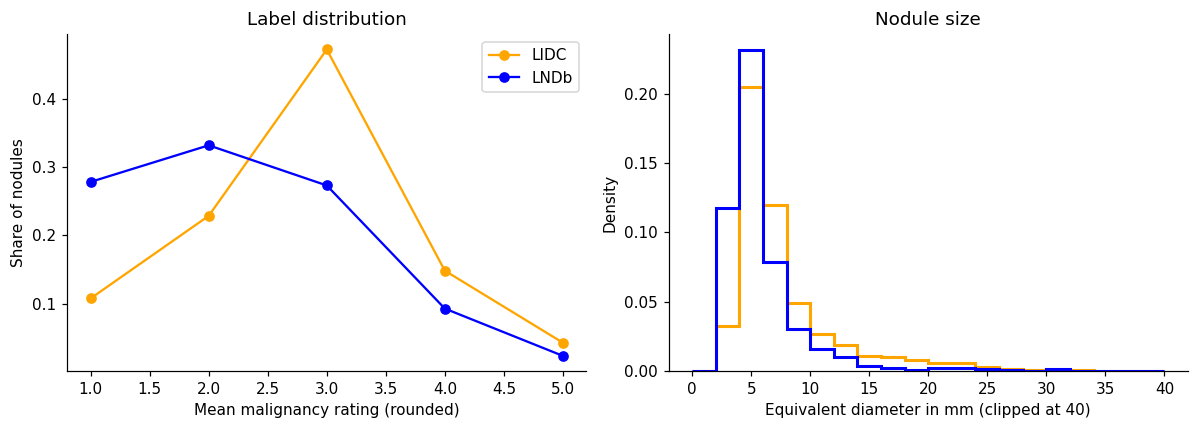

In [6]:
fig, (ax_label, ax_size) = plt.subplots(1, 2, figsize=(11, 4))

for name, group in nodules.groupby("dataset"):
    rounded = np.floor(group["mal_mean"].dropna() + 0.5)     # half up, so 2.5 becomes 3 and not 2
    share = rounded.value_counts(normalize=True).reindex(range(1, 6), fill_value=0)
    ax_label.plot(share.index, share.values, marker="o", color=COLORS[name], label=name)

    diameters = group["diameter_mm"].dropna().clip(upper=40)
    ax_size.hist(diameters, bins=np.arange(0, 41, 2), density=True,
                 histtype="step", linewidth=2, color=COLORS[name], label=name)

ax_label.set(xlabel="Mean malignancy rating (rounded)", ylabel="Share of nodules", title="Label distribution")
ax_size.set(xlabel="Equivalent diameter in mm (clipped at 40)", ylabel="Density", title="Nodule size")
ax_label.legend()
plt.tight_layout()
plt.show()

<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    The two datasets do not look alike. LNDb leans clearly towards benign ratings, while LIDC peaks at 3. Part of this is a side effect of averaging: LIDC nodules have on average about 2.6 ratings against 1.3 in LNDb, and a mean over several readers who disagree tends to land in the middle. LNDb also contains smaller nodules, which explains its smaller median diameter. Both effects matter when we train on one dataset and test on the other, so we now understand that we should not assume that a rating of 3 means the same thing in both.
  </p>
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Label Views
  </h3>
  <p>
    The model will be trained on 'mal_mean', which keeps the full 1 to 5 scale. For reporting we derive two main views from the same number: a ternary one built from the rating rounded half up, the same rounding used for training (benign for ratings 1 and 2, indeterminate for 3, malignant for 4 and 5, so a mean of 2.5 counts as 3) and a binary one that leaves the indeterminate band empty. Nothing is dropped from the table. If a model wants to ignore the indeterminate nodules it has to say so explicitly with 'label_binary.notna()'.
  </p>
</div>

In [7]:
rating = np.floor(table["mal_mean"] + 0.5)          # half up, as everywhere else: 2.5 becomes 3
table["label_ternary"] = pd.cut(rating, bins=[0, 2, 3, 5], labels=["benign", "indeterminate", "malignant"])
table["label_binary"] = table["label_ternary"].map({"benign": 0, "malignant": 1}).astype(float)

counts = pd.crosstab(table["dataset"], table["label_ternary"], margins=True)
percent = counts.div(counts["All"], axis=0).mul(100).round(0).drop(columns="All").add_suffix(" %")
counts.join(percent)

label_ternary,benign,indeterminate,malignant,All,benign %,indeterminate %,malignant %
dataset,,,,,,,
LIDC,896,1258,509,2663,34.0,47.0,19.0
LNDb,467,209,89,765,61.0,27.0,12.0
All,1363,1467,598,3428,40.0,43.0,17.0


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    LIDC has a much bigger indeterminate band than LNDb, which agrees with what the figure showed. This is one more reason to keep these nodules in the table and not to exclude them silently.
  </p>
</div>

In [8]:
if not OUTPUT.exists():                  # never overwrite the table used by the later parts
    table.to_csv(OUTPUT, index=False)
    print(f"Saved {len(table)} rows to {OUTPUT}")
else:
    print(f"{OUTPUT} already exists ({len(pd.read_csv(OUTPUT))} rows); kept as it is")

/home/anasofia/labiacd/mass_detect/notebooks/nodule_table.csv already exists (3882 rows); kept as it is


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   The training duplicates
  </h3>
  <p>
    12 training rows share a position with another row in the same CT. We checked what they are. In the LNDb files each finding comes from merging the readings of several radiologists, and readings are merged only if they agree on the type. When one radiologist marked a structure as a nodule and another marked the same place as a non nodule (or as a nodule smaller than 3 mm), the same lesion appears twice.
  </p>
</div>

In [9]:
table = pd.read_csv("nodule_table.csv")
lndb = table[table.dataset == "LNDb"]
from scipy.spatial.distance import cdist
pairs = []
for scan, g in lndb.groupby("scan_id"):
    c = g[["x_mm", "y_mm", "z_mm"]].values
    d = cdist(c, c); np.fill_diagonal(d, 99)
    for i, j in zip(*np.where(np.triu(d < 3))):
        pairs.append((g.mal_mean.notna().iloc[i], g.mal_mean.notna().iloc[j]))
pairs = pd.DataFrame(pairs, columns=["first_has_rating", "second_has_rating"])
print("pairs of rows closer than 3 mm in the same CT:", len(pairs))
print(pairs.value_counts().rename("pairs").to_string())

pairs of rows closer than 3 mm in the same CT: 59
first_has_rating  second_has_rating
True              False                47
False             True                 12


<div style="font-family: Arial, sans-serif; line-height: 1.6; color: #fab956; max-width: 1200px; margin: 0 auto; padding: 20px; border: 1px solid #000000; border-radius: 8px; background-color: #00183a74;">
  <p>
    In every pair, only one row has a malignancy rating and the other one has none. So the labelled nodules we train on never appear twice, and the duplicates cannot leak the same nodule between the training and validation folds. The unrated twin rows are simply not used for training. Validation is also grouped by CT, so even a hidden duplicate would stay on one side.
  </p>
  
  <h3 style="color: #f0f0f0; font-weight: normal; margin-top: -5px; margin-bottom: 20px;">
   Limits to keep in mind
  </h3>
  <ol style="padding-left: 20px; margin-bottom: 20px;">
    <li style="margin-bottom: 8px;">The datasets do not measure exactly the same thing. LIDC only contains nodules of 3 mm or more, read by up to four radiologists. LNDb also includes smaller nodules and non nodules, and most of its nodules were read by a single radiologist. The label is therefore noisier in LNDb.</li>
    <li style="margin-bottom: 8px;">The regrouped LIDC nodules rest on a heuristic. They are marked in 'reclustered', and a sensitivity analysis with and without them is planned. The few groups that stay above four annotations are kept and flagged in 'oversized_group'. One of them probably mixes several nodules.</li>
    <li style="margin-bottom: 8px;">Coordinates come from each dataset's own frame. They are only meaningful together with their own CT, which is all we need to cut patches.</li>
    <li style="margin-bottom: 8px;">Validation must group by 'patient_id'. Rows from the same patient share scanner and anatomy.</li>
    <li style="margin-bottom: 8px;">Scanners differ a lot. LNDb comes from one hospital and three Siemens models. LIDC mixes many vendors. Any gain from adding LIDC has to be measured on LNDb scans held out by CT.</li>
  </ol>
</div>